# Alfa Connectome — LSTM 2×128 / Colab T4
Выполняйте сверху вниз. Полное обучение — 5 эпох float32, TBPTT 1000, batch 32.
**Не проверено запуском на Colab T4.** Локальные численные тесты описаны в STATUS.md.
Загрузите папку `alfa_codex_handoff` на Google Drive (без .venv), а также исходные train/valid Parquet либо укажите URL. Нужны около 58 GB для подготовленных массивов плюс место для исходных Parquet, Drive и checkpoint. Бесплатной квоты Drive может не хватить.
Чекпоинт фиксируется после каждого полного batch. При обрыве повторяется только работа после последней записи; состояние LSTM внутри незаконченного batch не восстанавливается.


In [ ]:

from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path

# Исходники проекта и готовые файлы команды — Google Drive
PROJECT = Path('/content/drive/MyDrive/alfa_codex_handoff')
ASSETS = PROJECT / 'assets/valid300'

# Датасет и подготовленные массивы — локальный диск Colab
RAW = Path('/content/data/raw')
DATA = Path('/content/data/prepared')
ARCHIVE = Path('/content/data/wnn_connectome_starterpack.tar.gz')

# Где искать уже скачанные данные
SEARCH = [
    RAW,
    Path('/content/wnn_connectome_starterpack'),
    Path('/content/data'),
]

# Чекпоинты и результаты — Google Drive
OUT = Path('/content/drive/MyDrive/alfa_lstm_run')

# Официальный архив
ARCHIVE_URL = 'https://files.wundernn.io/wnn_connectome_starterpack.tar.gz'

# Создаём необходимые папки
RAW.mkdir(parents=True, exist_ok=True)
DATA.mkdir(parents=True, exist_ok=True)
OUT.mkdir(parents=True, exist_ok=True)

# Проверяем исходники
assert (PROJECT / 'src/train.py').is_file(), \
    'Не найден src/train.py. Проверьте папку проекта на Google Drive.'

print('Настройка завершена.')
print('Проект:', PROJECT)
print('Данные:', DATA)
print('Чекпоинты:', OUT)
print('Файлы valid300:', ASSETS.exists())


Mounted at /content/drive
Настройка завершена.
Проект: /content/drive/MyDrive/alfa_codex_handoff
Данные: /content/data/prepared
Чекпоинты: /content/drive/MyDrive/alfa_lstm_run
Файлы valid300: True


In [ ]:
%pip -q install "numpy<2.4" "numba==0.67.0" pyarrow tqdm matplotlib pytest
import os,sys,subprocess,json,shutil
os.environ['CUBLAS_WORKSPACE_CONFIG']=':4096:8'
os.environ['OMP_NUM_THREADS']='1'
os.environ['OPENBLAS_NUM_THREADS']='1'
import torch
assert torch.cuda.is_available() and 'T4' in torch.cuda.get_device_name(), 'Выберите Colab T4'
print(torch.__version__, torch.cuda.get_device_name())
OUT.mkdir(parents=True,exist_ok=True)
(OUT/'environment.txt').write_text(subprocess.check_output([sys.executable,'-m','pip','freeze'],text=True))
def run(*args): subprocess.run([sys.executable,*map(str,args)],cwd=PROJECT,check=True)
print('Local free GB', shutil.disk_usage('/content').free/1e9)
print('Drive free GB', shutil.disk_usage(OUT).free/1e9)


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cuml-cu13 26.6.0 requires numba<0.65.0,>=0.60.0, but you have numba 0.67.0 which is incompatible.
pytensor 2.38.3 requires numba<=0.65.1,>=0.58, but you have numba 0.67.0 which is incompatible.
cudf-cu13 26.6.0 requires numba<0.65.0,>=0.60.0, but you have numba 0.67.0 which is incompatible.
2.14.1+cu130 Tesla T4
Local free GB 120.462290944
Drive free GB 114.439176192


In [ ]:
run('-m','pytest','tests','-q')


## Данные и фиксированный holdout
300 sorted valid row groups никогда не входят в обучение. Проверяются footer, количество групп, порядок 112 признаков, длины и шаги последовательностей. Подготовка завершена только при наличии manifest.json.

Архив скачивается отдельно через curl HTTP/1.1 с повторами и Range resume. До извлечения проверяется полный gzip CRC и каталог tar. Существующий корректный train сохраняется, повреждённый valid заменяется. Train не требует is_scored. Архив и подготовленные данные лежат на Drive; исходные Parquet можно держать локально. Для архива + prepared требуется более 90 GB Drive; проверьте квоту в интерфейсе Drive, statvfs может показывать неточную квоту.

In [ ]:
if not (DATA/'manifest.json').exists():
    run('scripts/acquire_data.py','--url',ARCHIVE_URL,'--archive',ARCHIVE,'--out',RAW,'--search',*SEARCH)
    run('scripts/prepare_data.py','--source',RAW,'--out',DATA)
else:
    print('Используем подготовленные данные на Drive:', DATA)


CalledProcessError: Command '['/usr/bin/python3', 'scripts/prepare_data.py', '--source', '/content/data/raw', '--out', '/content/data/prepared']' returned non-zero exit status 1.

In [ ]:

import sys
import shutil
import subprocess
from pathlib import Path

print("=== ПРИЧИНА ПРЕДЫДУЩЕЙ ОШИБКИ ===")
err = getattr(sys, "last_value", None)

if isinstance(err, subprocess.CalledProcessError):
    for name in ("stdout", "stderr"):
        value = getattr(err, name, None)
        if value:
            if isinstance(value, bytes):
                value = value.decode(errors="replace")
            print(f"\n{name} (последние 6000 символов):")
            print(value[-6000:])
else:
    print("Предыдущий вывод ошибки недоступен.")

print("\n=== СВОБОДНОЕ МЕСТО ===")
total, used, free = shutil.disk_usage("/content")
print(f"Всего: {total / 1024**3:.1f} ГБ")
print(f"Занято: {used / 1024**3:.1f} ГБ")
print(f"Свободно: {free / 1024**3:.1f} ГБ")

print("\n=== ФАЙЛЫ ДАТАСЕТА ===")

for folder in [RAW, DATA]:
    print(f"\nПапка: {folder}")
    print("Существует:", folder.exists())

    if folder.exists():
        for p in sorted(folder.iterdir()):
            if p.is_file():
                print(
                    p.name,
                    f"{p.stat().st_size / 1024**3:.3f} ГБ"
                )
            else:
                print(p.name, "(папка)")

print("\n=== ПРОВЕРКА PARQUET ===")

try:
    import pyarrow.parquet as pq

    for name in ("train.parquet", "valid.parquet"):
        matches = list(RAW.rglob(name))

        if not matches:
            print(f"{name}: НЕ НАЙДЕН")
            continue

        for path in matches:
            try:
                pf_check = pq.ParquetFile(str(path))
                print(
                    f"{name}: OK, "
                    f"row groups = {pf_check.num_row_groups}"
                )
            except Exception as e:
                print(f"{name}: ОШИБКА: {repr(e)}")

except Exception as e:
    print("Ошибка проверки:", repr(e))


=== ПРИЧИНА ПРЕДЫДУЩЕЙ ОШИБКИ ===

=== СВОБОДНОЕ МЕСТО ===
Всего: 112.6 ГБ
Занято: 64.4 ГБ
Свободно: 48.3 ГБ

=== ФАЙЛЫ ДАТАСЕТА ===

Папка: /content/data/raw
Существует: True
raw_paths.json 0.000 ГБ
train.parquet 27.232 ГБ
valid.parquet 5.230 ГБ

Папка: /content/data/prepared
Существует: True

=== ПРОВЕРКА PARQUET ===
train.parquet: OK, row groups = 10607
valid.parquet: OK, row groups = 1873


In [ ]:

from pathlib import Path
import shutil
import pyarrow.parquet as pq

print("=== ПРОВЕРКА ДАТАСЕТОВ ===")

for name, expected in [
    ("train.parquet", 10607),
    ("valid.parquet", 1873)
]:
    path = RAW / name
    pf_check = pq.ParquetFile(path)

    assert pf_check.num_row_groups == expected

    last = pf_check.read_row_group(
        expected - 1,
        columns=["t0", "t1"]
    )

    assert last.num_rows == 20000
    print(f"{name}: OK, последняя последовательность читается")

print("\n=== АРХИВ ===")

if ARCHIVE.is_file():
    size = ARCHIVE.stat().st_size / 1024**3
    print(f"Найден архив: {size:.2f} ГБ")
    ARCHIVE.unlink()
    print("Архив удалён. Parquet-файлы сохранены.")
else:
    print("Архива на указанном пути нет.")

print("\n=== СВОБОДНОЕ МЕСТО ===")
free = shutil.disk_usage("/content").free / 1024**3
print(f"Свободно: {free:.1f} ГБ")


=== ПРОВЕРКА ДАТАСЕТОВ ===
train.parquet: OK, последняя последовательность читается
valid.parquet: OK, последняя последовательность читается

=== АРХИВ ===
Найден архив: 31.42 ГБ
Архив удалён. Parquet-файлы сохранены.

=== СВОБОДНОЕ МЕСТО ===
Свободно: 79.7 ГБ


In [ ]:

import subprocess
import sys
import shutil

print("=== ПОДГОТОВКА ДАННЫХ ===")
print(f"Источник: {RAW}")
print(f"Результат: {DATA}")
print(f"Свободно: {shutil.disk_usage('/content').free / 1024**3:.1f} ГБ")

assert (RAW / "train.parquet").is_file()
assert (RAW / "valid.parquet").is_file()

cmd = [
    sys.executable,
    "-u",
    str(PROJECT / "scripts/prepare_data.py"),
    "--source", str(RAW),
    "--out", str(DATA)
]

result = subprocess.run(cmd, cwd=str(PROJECT), check=False)

print("\n=== РЕЗУЛЬТАТ ===")
print("Код завершения:", result.returncode)
print("Manifest создан:", (DATA / "manifest.json").is_file())
print(f"Свободно: {shutil.disk_usage('/content').free / 1024**3:.1f} ГБ")


=== ПОДГОТОВКА ДАННЫХ ===
Источник: /content/data/raw
Результат: /content/data/prepared
Свободно: 79.7 ГБ

=== РЕЗУЛЬТАТ ===
Код завершения: 0
Manifest создан: True
Свободно: 25.8 ГБ


In [ ]:

import torch
import json
import shutil

print("=== ПРОВЕРКА ПЕРЕД ОБУЧЕНИЕМ ===")

assert (DATA / "manifest.json").is_file(), "Нет manifest.json"
assert (PROJECT / "src/train.py").is_file(), "Нет train.py"

with open(DATA / "manifest.json") as f:
    manifest = json.load(f)

print("Данные подготовлены: OK")
print("Manifest:", list(manifest.keys()))

print("\nGPU доступен:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("Видеокарта:", torch.cuda.get_device_name(0))

print("\nЧекпоинты:", OUT)
print("Папка существует:", OUT.is_dir())

free = shutil.disk_usage("/content").free / 1024**3
print(f"\nСвободно на диске: {free:.1f} ГБ")

assert torch.cuda.is_available(), "GPU не подключён!"
assert OUT.is_dir(), "Нет папки для чекпоинтов!"

print("\nГОТОВО К ОБУЧЕНИЮ")


=== ПРОВЕРКА ПЕРЕД ОБУЧЕНИЕМ ===
Данные подготовлены: OK
Manifest: ['features', 'holdout', 'counts', 'length', 'dtype', 'source_sizes']

GPU доступен: True
Видеокарта: Tesla T4

Чекпоинты: /content/drive/MyDrive/alfa_lstm_run
Папка существует: True

Свободно на диске: 25.8 ГБ

ГОТОВО К ОБУЧЕНИЮ


## Обучение / продолжение
Повторный запуск автоматически использует checksummed last.json. Параметры и fingerprint manifest обязаны совпадать. ETA приблизительная. Checkpoint хранит модель, Adam, OneCycleLR, RNG и следующую позицию batch. Версионный best.json указывает на лучший best-*.pt; это эквивалент best.pt с безопасной записью на Drive.

In [ ]:
args=['src/train.py','--model','lstm','--hidden','128','--seed','0','--epochs','5','--data_dir',DATA,'--out',OUT,'--checkpoint_interval','1']
if (OUT/'last.json').exists(): args += ['--resume']
run(*args)


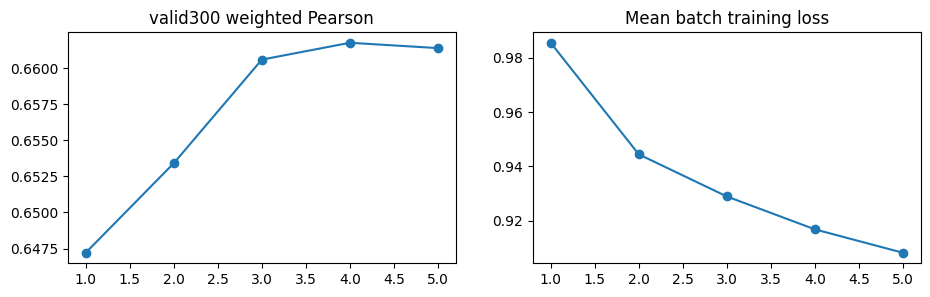

In [ ]:
import matplotlib.pyplot as plt
history=json.loads((OUT/'history.json').read_text())
fig,ax=plt.subplots(1,2,figsize=(11,3))
ax[0].plot([h['epoch'] for h in history],[h['score'] for h in history],marker='o'); ax[0].set_title('valid300 weighted Pearson')
ax[1].plot([h['epoch'] for h in history],[h['train_loss'] for h in history],marker='o'); ax[1].set_title('Mean batch training loss')
plt.show()


## Честное сравнение
Baseline предварительно умножается на 0.3. Сравниваются три независимых прогноза и равновесный ансамбль с LSTM. Partner/Mamba без гарантии отсутствия утечки не включаются. Прирост <0.003 считается неустойчивым; bootstrap не заменяет вторую независимую проверку.

In [ ]:
run('scripts/validate.py','--assets',ASSETS,'--lstm',OUT/'P_lstm_valid300.npy','--provenance',OUT/'prediction_provenance.json','--out',OUT/'validation.json')
run('scripts/export_checkpoint.py','--checkpoint-dir',OUT,'--out',OUT/'lstm_weights.npz')
run('scripts/verify_export.py','--weights',OUT/'lstm_weights.npz','--data-dir',DATA,'--prediction',OUT/'P_lstm_valid300.npy','--out',OUT/'verification.json')
run('scripts/benchmark.py','--weights',OUT/'lstm_weights.npz','--out',OUT/'benchmark.json')


In [ ]:

import sys
import subprocess
from pathlib import Path

print("=== ПРОВЕРКА ФАЙЛОВ ===")

files = {
    "Предсказания LSTM": OUT / "P_lstm_valid300.npy",
    "Информация о предсказаниях": OUT / "prediction_provenance.json",
    "Истинные цели": ASSETS / "valid300_Y.npy",
    "Маска оценки": ASSETS / "valid300_M.npy",
    "Скрипт проверки": PROJECT / "scripts/validate.py",
}

for name, path in files.items():
    if path.is_file():
        size = path.stat().st_size / 1024**2
        print(f"OK  {name}: {size:.1f} МБ")
    else:
        print(f"НЕТ {name}: {path}")

print("\n=== ДИАГНОСТИКА VALIDATE.PY ===")

cmd = [
    sys.executable, "-u",
    "scripts/validate.py",
    "--assets", str(ASSETS),
    "--lstm", str(OUT / "P_lstm_valid300.npy"),
    "--provenance", str(OUT / "prediction_provenance.json"),
    "--out", str(OUT / "validation.json"),
]

if all(path.is_file() for path in files.values()):
    result = subprocess.run(
        cmd,
        cwd=str(PROJECT),
        capture_output=True,
        text=True,
        check=False
    )

    print("Код завершения:", result.returncode)
    print("\nSTDOUT:")
    print(result.stdout[-6000:])
    print("\nSTDERR:")
    print(result.stderr[-8000:])
else:
    print("Проверка не запущена: отсутствуют необходимые файлы.")


=== ПРОВЕРКА ФАЙЛОВ ===
OK  Предсказания LSTM: 45.8 МБ
OK  Информация о предсказаниях: 0.0 МБ
НЕТ Истинные цели: /content/drive/MyDrive/alfa_codex_handoff/assets/valid300/valid300_Y.npy
НЕТ Маска оценки: /content/drive/MyDrive/alfa_codex_handoff/assets/valid300/valid300_M.npy
OK  Скрипт проверки: 0.0 МБ

=== ДИАГНОСТИКА VALIDATE.PY ===
Проверка не запущена: отсутствуют необходимые файлы.


## Финальная сборка — отдельный обязательный этап
`lstm_weights.npz` выше содержит **одну LSTM**, тогда как quality gain измерен для ансамбля из четырёх моделей. Эти результаты нельзя использовать как доказательство качества одиночной модели.
Для финального ZIP нужны веса всех выбранных независимых моделей, точное соответствие ансамбля проверенным прогнозам, CPU benchmark всего ансамбля и parity на valid300. В handoff не предоставлены отдельные checkpoints честного ансамбля; экспорт из нескольких собственных checkpoints доступен через `scripts/export_ensemble.py`.
`scripts/build_submission.py` требует отчёт о валидации именно экспортированного кандидата и откажет без проверок. Финальная сборка не запускается автоматически из результатов одиночной LSTM. См. `scripts/README.md`.


In [ ]:

import json

print("=== РЕЗУЛЬТАТЫ LSTM ===")

for name in [
    "validation.json",
    "verification.json",
    "benchmark.json"
]:
    path = OUT / name

    print(f"\n{'=' * 15} {name} {'=' * 15}")

    if path.is_file():
        with open(path) as f:
            print(json.dumps(json.load(f), indent=2, ensure_ascii=False))
    else:
        print("Файл не найден")

print("\n=== СОХРАНЁННЫЕ ФАЙЛЫ ===")

for name in [
    "P_lstm_valid300.npy",
    "lstm_weights.npz",
    "last.json",
    "best.pt"
]:
    path = OUT / name
    print(name, "OK" if path.exists() else "Не найден")


=== РЕЗУЛЬТАТЫ LSTM ===

=============== validation.json ===============
{
  "scores": {
    "b": [
      0.6531160535766264,
      0.6612840643917636
    ],
    "gru6573": [
      0.6523875111979047,
      0.6614891543466825
    ],
    "corr3k": [
      0.6503052293382263,
      0.6578833700618969
    ],
    "gruall": [
      0.6515803814195648,
      0.6623916078379651
    ],
    "gruev": [
      0.6546049418663471,
      0.6653649253015131
    ],
    "gruh256": [
      0.6553908650618143,
      0.6648207286483917
    ],
    "honest3": [
      0.6566892611209662,
      0.6652966669344217
    ],
    "lstm": [
      0.6574181779358008,
      0.6660981183918814
    ],
    "honest3_plus_lstm": [
      0.6588336468116792,
      0.6672391726303838
    ]
  },
  "family_counts": [
    68,
    54,
    80,
    98
  ],
  "holdout": [
    10,
    12,
    31,
    42,
    43,
    54,
    55,
    65,
    72,
    80,
    90,
    100,
    103,
    109,
    115,
    124,
    127,
    131,
    136,
   

In [ ]:

import json

weights = OUT / "lstm_weights_float32.npz"
report = OUT / "verification_float32.json"

assert not weights.exists() and not report.exists(), \
    "Эти файлы уже существуют — проверь предыдущий запуск"

print("=== ЭКСПОРТ FLOAT32 ===")

run(
    "scripts/export_checkpoint.py",
    "--checkpoint-dir", OUT,
    "--float32",
    "--out", weights
)

print("\n=== ПРОВЕРКА NUMBA ===")

run(
    "scripts/verify_export.py",
    "--weights", weights,
    "--data-dir", DATA,
    "--prediction", OUT / "P_lstm_valid300.npy",
    "--out", report
)

with open(report) as f:
    result = json.load(f)

print("\n=== РЕЗУЛЬТАТ ===")
print("Максимальная ошибка:", result["max_error"])
print("Проверка пройдена:", result["passed"])
print("Время проверки:", result["elapsed_seconds"], "сек.")


NameError: name 'OUT' is not defined

In [ ]:
from google.colab import drive
from pathlib import Path

drive.mount('/content/drive')

PROJECT = Path('/content/drive/MyDrive/alfa_codex_handoff')
OUT = Path('/content/drive/MyDrive/alfa_lstm_run')
DATA = Path('/content/data/prepared')

print("=== ПРОВЕРКА ПОСЛЕ ПЕРЕЗАПУСКА ===")

print("Проект:", PROJECT.exists())
print("Результаты LSTM:", OUT.exists())

print("\nЧекпоинты:")
for f in sorted(OUT.glob("best*.pt")):
    print(" ", f.name)

print("\nПредсказания LSTM:",
      (OUT / "P_lstm_valid300.npy").exists())

print("Исправленный экспорт:",
      (PROJECT / "scripts/export_checkpoint.py").exists())

print("\nПодготовленные данные:",
      (DATA / "manifest.json").exists())

print("\nФайлы в /content/data:")
data_root = Path("/content/data")
if data_root.exists():
    for f in data_root.iterdir():
        print(" ", f.name)
else:
    print("Папка отсутствует")

Mounted at /content/drive
=== ПРОВЕРКА ПОСЛЕ ПЕРЕЗАПУСКА ===
Проект: True
Результаты LSTM: True

Чекпоинты:
  best-851ecc7d811b48fe92f4a817365d069e.pt
  best-dd76e3373cbe4a0994ff229df1ea9a9d.pt

Предсказания LSTM: True
Исправленный экспорт: True

Подготовленные данные: False

Файлы в /content/data:
Папка отсутствует


In [ ]:

from pathlib import Path
import subprocess
import sys
import json
import hashlib

PROJECT = Path("/content/drive/MyDrive/alfa_codex_handoff")
OUT = Path("/content/drive/MyDrive/alfa_lstm_run")

# Проверяем сохранённый чекпоинт
provenance = json.loads(
    (OUT / "prediction_provenance.json").read_text()
)

checkpoint_info = provenance["checkpoint"]
checkpoint = OUT / checkpoint_info["file"]

assert checkpoint.is_file(), "Чекпоинт не найден"

actual_hash = hashlib.sha256(
    checkpoint.read_bytes()
).hexdigest()

assert actual_hash == checkpoint_info["sha256"], \
    "Чекпоинт не совпадает с использованным для прогнозов"

print("Эталонный чекпоинт:", checkpoint.name)
print("SHA256 совпадает: OK")

# Экспортируем новые веса, не затрагивая старые
weights = OUT / "lstm_weights_float32.npz"

assert not weights.exists(), \
    "Файл уже существует — не перезаписываем"

cmd = [
    sys.executable, "-u",
    "scripts/export_checkpoint.py",
    "--checkpoint-dir", str(OUT),
    "--float32",
    "--out", str(weights)
]

print("\n=== ЭКСПОРТ FLOAT32 ===")

result = subprocess.run(
    cmd,
    cwd=str(PROJECT),
    capture_output=True,
    text=True
)

print(result.stdout)
print(result.stderr)

print("Код завершения:", result.returncode)
print("Новые веса созданы:", weights.is_file())

if weights.is_file():
    print(
        "Размер:",
        round(weights.stat().st_size / 1024**2, 2),
        "МБ"
    )


Эталонный чекпоинт: best-dd76e3373cbe4a0994ff229df1ea9a9d.pt
SHA256 совпадает: OK


AssertionError: Файл уже существует — не перезаписываем

In [ ]:
import numpy as np
import json

weights = OUT / "lstm_weights_float32.npz"
report = OUT / "verification_float32.json"

print("=== ВЕСА FLOAT32 ===")
print("Файл существует:", weights.is_file())

if weights.is_file():
    print("Размер:", round(weights.stat().st_size / 1024**2, 2), "МБ")

    try:
        with np.load(weights, allow_pickle=False) as z:
            from collections import Counter

            dtypes = Counter(
                str(z[k].dtype)
                for k in z.files
                if np.issubdtype(z[k].dtype, np.floating)
            )
            print("Типы числовых весов:", dict(dtypes))
            print("Количество массивов:", len(z.files))
    except Exception as e:
        print("Ошибка чтения весов:", repr(e))

print("\n=== ПРОВЕРКА ЭКСПОРТА ===")
print("Отчёт существует:", report.is_file())

if report.is_file():
    with open(report) as f:
        result = json.load(f)

    print("Максимальная ошибка:", result.get("max_error"))
    print("Проверка пройдена:", result.get("passed"))

=== ВЕСА FLOAT32 ===
Файл существует: True
Размер: 0.98 МБ
Типы числовых весов: {'float32': 7, 'float64': 2}
Количество массивов: 11

=== ПРОВЕРКА ЭКСПОРТА ===
Отчёт существует: False


In [ ]:

import numpy as np

old_path = OUT / "lstm_weights.npz"
new_path = OUT / "lstm_weights_float32.npz"

with np.load(old_path, allow_pickle=False) as old, \
     np.load(new_path, allow_pickle=False) as new:

    print("=== СРАВНЕНИЕ ВЕСОВ ===")

    for key in old.files:
        if key not in new.files:
            print(key, "ОТСУТСТВУЕТ В НОВОМ ФАЙЛЕ")
            continue

        a, b = old[key], new[key]

        if a.shape != b.shape:
            print(key, "РАЗНЫЕ РАЗМЕРНОСТИ")
            continue

        if np.issubdtype(a.dtype, np.number) and \
           np.issubdtype(b.dtype, np.number):
            diff = np.max(
                np.abs(a.astype(np.float64) -
                       b.astype(np.float64))
            )
            print(
                key,
                f"{a.dtype} -> {b.dtype}",
                f"max_diff={diff:.8f}"
            )

print("\nСравнение завершено.")


=== СРАВНЕНИЕ ВЕСОВ ===
flat float32 -> float32 max_diff=0.00000000
mats uint16 -> float32 max_diff=49306.29624248
meta int64 -> int64 max_diff=0.00000000
mods int64 -> int64 max_diff=0.00000000
coef float32 -> float32 max_diff=0.00000000
const float32 -> float32 max_diff=0.00000000
selftest_x float32 -> float32 max_diff=0.00000000
selftest_y float32 -> float32 max_diff=0.00049092
cross_mix float32 -> float32 max_diff=0.00000000
ev_mu float64 -> float64 max_diff=0.00000000
ev_sd float64 -> float64 max_diff=0.00000000

Сравнение завершено.


In [ ]:

import numpy as np

with np.load(OUT / "lstm_weights.npz") as old, \
     np.load(OUT / "lstm_weights_float32.npz") as new:

    old_bits = old["mats"]
    old_weights = old_bits.view(np.float16).astype(np.float32)
    new_weights = new["mats"].astype(np.float32)

    assert old_weights.shape == new_weights.shape

    diff = np.abs(old_weights - new_weights)

    print("Максимальная разница:", diff.max())
    print("Средняя разница:", diff.mean())

    restored_bits = new_weights.astype(np.float16).view(np.uint16)

    print(
        "Веса совпадают после округления до float16:",
        np.array_equal(old_bits, restored_bits)
    )
    print(
        "Количество несовпадающих элементов:",
        np.count_nonzero(old_bits != restored_bits)
    )


Максимальная разница: 0.0008034706
Средняя разница: 2.8568782e-05
Веса совпадают после округления до float16: True
Количество несовпадающих элементов: 0


In [ ]:

import subprocess
import sys
import numpy as np

with np.load(OUT / "lstm_weights_float32.npz") as z:
    print("=== ВСТРОЕННЫЕ ТЕСТОВЫЕ ДАННЫЕ ===")
    print("selftest_x:", z["selftest_x"].shape)
    print("selftest_y:", z["selftest_y"].shape)

print("\n=== ВОЗМОЖНОСТИ ПРОВЕРКИ ===")

result = subprocess.run(
    [sys.executable, "scripts/verify_export.py", "--help"],
    cwd=str(PROJECT),
    capture_output=True,
    text=True
)

print(result.stdout)
print(result.stderr)


=== ВСТРОЕННЫЕ ТЕСТОВЫЕ ДАННЫЕ ===
selftest_x: (8, 112)
selftest_y: (8, 2)

=== ВОЗМОЖНОСТИ ПРОВЕРКИ ===
usage: verify_export.py [-h] --weights WEIGHTS --data-dir DATA_DIR
                        --prediction PREDICTION --out OUT

options:
  -h, --help            show this help message and exit
  --weights WEIGHTS
  --data-dir DATA_DIR
  --prediction PREDICTION
  --out OUT




In [ ]:

from pathlib import Path

p = PROJECT / "scripts/verify_export.py"

print("=== VERIFY_EXPORT.PY ===")
print(p.read_text())

print("\n=== ФАЙЛЫ SRC ===")
for f in sorted((PROJECT / "src").glob("*.py")):
    print(f.name)


=== VERIFY_EXPORT.PY ===
"""Compare exported engine with saved torch predictions on all real held-out X."""
import argparse,json,sys,time
from pathlib import Path
sys.path.insert(0,str(Path(__file__).resolve().parents[1]/'src'))
import numpy as np
from types import SimpleNamespace
from tqdm.auto import tqdm
from solution import PredictionModel
from data import HOLDOUT
from checkpoint import digest

if __name__=='__main__':
    p=argparse.ArgumentParser()
    for k in ('weights','data-dir','prediction','out'): p.add_argument('--'+k,required=True)
    a=p.parse_args(); root=Path(a.data_dir)
    if json.loads((root/'manifest.json').read_text())['holdout']!=HOLDOUT.tolist(): raise ValueError('Wrong holdout')
    x=np.load(root/'valid300_X.npy',mmap_mode='r'); y=np.load(a.prediction,mmap_mode='r')
    if x.shape!=(300,20000,112) or y.shape!=(300,20000,2) or y.dtype!=np.float32: raise ValueError('Wrong shape/dtype')
    e=PredictionModel(a.weights); err=0.; start=time.monotonic()
    for i i

In [ ]:
for name in ["models.py", "solution.py"]:
    path = PROJECT / "src" / name
    print(f"\n===== {name} =====")
    print(path.read_text())


===== models.py =====
import torch
from torch import nn

class Net(nn.Module):
    def __init__(self, model='lstm', hidden=128):
        super().__init__()
        self.kind, self.hidden = model, hidden
        self.rnn = (nn.LSTM if model == 'lstm' else nn.GRU)(120 if model == 'gru_ev' else 112, hidden, 2, batch_first=True)
        self.head = nn.Linear(hidden, 2)

    def forward(self, x, state=None):
        y, state = self.rnn(x.float(), state)
        return self.head(y), state


def detach(state):
    return tuple(s.detach() for s in state) if isinstance(state, tuple) else state.detach()


===== solution.py =====
"""Blend of recurrent models, one row at a time, compiled with numba (written by build_ensemble.py).

The scorer image has numba (its requirements.txt pins numba==0.67.0). One compiled call per row
runs every model and the blend, so there is no per-operation overhead of numpy/onnxruntime:
  * matrix-vector products are "axpy" loops over transposed weights, 8 input rows 

In [ ]:

import sys
import numpy as np
from types import SimpleNamespace

sys.path.insert(0, str(PROJECT / "src"))
from solution import PredictionModel

weights = OUT / "lstm_weights_float32.npz"

with np.load(weights, allow_pickle=False) as z:
    X = z["selftest_x"].copy()
    Y = z["selftest_y"].copy()
    print("cross_mix в файле:", float(z["cross_mix"]))

model = PredictionModel(str(weights))

raw_preds = []
final_preds = []

for t in range(len(X)):
    pred = model.predict(
        SimpleNamespace(
            seq_ix=0,
            state=X[t],
            need_prediction=True
        )
    )
    raw_preds.append(model.out.copy())
    final_preds.append(pred.copy())

raw_preds = np.array(raw_preds)
final_preds = np.array(final_preds)

print("\n=== СРАВНЕНИЕ ===")
print("Ошибка ДО cross_mix:",
      np.max(np.abs(raw_preds - Y)))
print("Ошибка ПОСЛЕ cross_mix:",
      np.max(np.abs(final_preds - Y)))

print("\nПервые прогнозы:")
print("PyTorch:", Y[0])
print("Numba без смешивания:", raw_preds[0])
print("Numba после смешивания:", final_preds[0])


cross_mix в файле: 0.0

=== СРАВНЕНИЕ ===
Ошибка ДО cross_mix: 3.3900142e-07
Ошибка ПОСЛЕ cross_mix: 3.3900142e-07

Первые прогнозы:
PyTorch: [-0.9505671  1.4492303]
Numba без смешивания: [-0.9505671  1.4492302]
Numba после смешивания: [-0.9505671  1.4492302]


In [ ]:

import sys
import numpy as np
import torch
from types import SimpleNamespace
from tqdm.auto import tqdm

sys.path.insert(0, str(PROJECT / "src"))
from models import Net
from solution import PredictionModel

torch.set_num_threads(1)
weights = OUT / "lstm_weights_float32.npz"

with np.load(weights, allow_pickle=False) as z:
    mats = z["mats"].copy()
    flat = z["flat"].copy()
    meta = z["meta"].copy()
    mods = z["mods"].copy()
    coef = z["coef"].copy()
    const = z["const"].copy()
    cross_mix = float(z["cross_mix"])
    test_x = z["selftest_x"].copy()
    test_y = z["selftest_y"].copy()

assert mods.shape[0] == 1 and mods[0, 0] == 3
r = int(mods[0, 1])
H = int(mods[0, 3])

def get_mat(k):
    offset, n, m = map(int, meta[r + k])
    return mats[offset:offset + n*m].reshape(n, m).copy()

def get_vec(k):
    offset, n, m = map(int, meta[r + k])
    return flat[offset:offset + n*m].copy()

net = Net(model="lstm", hidden=H).eval()

with torch.no_grad():
    for layer in range(2):
        k = layer * 4
        getattr(net.rnn, f"weight_ih_l{layer}").copy_(
            torch.from_numpy(get_mat(k).T.copy())
        )
        getattr(net.rnn, f"weight_hh_l{layer}").copy_(
            torch.from_numpy(get_mat(k + 1).T.copy())
        )
        getattr(net.rnn, f"bias_ih_l{layer}").copy_(
            torch.from_numpy(get_vec(k + 2))
        )
        getattr(net.rnn, f"bias_hh_l{layer}").copy_(
            torch.from_numpy(get_vec(k + 3))
        )

    net.head.weight.copy_(
        torch.from_numpy(get_mat(8).T.copy())
    )
    net.head.bias.copy_(
        torch.from_numpy(get_vec(9))
    )

def torch_predict(X):
    with torch.inference_mode():
        y = net(torch.from_numpy(X[None]))[0][0].numpy()

    y = y * coef[0] + const
    p, q = y[:, 0].copy(), y[:, 1].copy()
    a = cross_mix

    return np.stack([
        (1-a)*p-a*q,
        (1-a)*q-a*p
    ], axis=1).astype(np.float32)

# Сначала проверяем правильность восстановления PyTorch
short_error = np.max(np.abs(
    torch_predict(test_x) - test_y
))
print("Ошибка восстановления PyTorch:", short_error)
assert short_error < 1e-3

# 20 000 шагов: тестовые входы с небольшими вариациями
rng = np.random.default_rng(42)
X = np.tile(test_x, (2500, 1)).astype(np.float32)
X += rng.normal(0, 0.01, X.shape).astype(np.float32)

print("\nВычисляем PyTorch...")
Y_torch = torch_predict(X)

print("Вычисляем Numba...")
engine = PredictionModel(str(weights))
Y_numba = np.empty_like(Y_torch)

for t in tqdm(range(len(X)), desc="Numba 20000 steps"):
    Y_numba[t] = engine.predict(
        SimpleNamespace(
            seq_ix=0,
            state=X[t],
            need_prediction=True
        )
    )

errors = np.max(np.abs(Y_torch - Y_numba), axis=1)

print("\n=== РЕЗУЛЬТАТ ===")
for n in [100, 1000, 5000, 10000, 20000]:
    print(f"{n:5d} шагов: max_error = {errors[:n].max():.8f}")

print("\nОбщая максимальная ошибка:", errors.max())
print("Порог 0.001 пройден:", bool(errors.max() < 1e-3))


Ошибка восстановления PyTorch: 1.1920929e-07

Вычисляем PyTorch...
Вычисляем Numba...


Numba 20000 steps:   0%|          | 0/20000 [00:00<?, ?it/s]


=== РЕЗУЛЬТАТ ===
  100 шагов: max_error = 0.00000089
 1000 шагов: max_error = 0.00000089
 5000 шагов: max_error = 0.00000131
10000 шагов: max_error = 0.00000131
20000 шагов: max_error = 0.00000131

Общая максимальная ошибка: 1.3113022e-06
Порог 0.001 пройден: True


In [ ]:

import subprocess
import sys

scripts = [
    "scripts/export_ensemble.py",
    "scripts/build_ensemble.py",
    "scripts/build_submission.py",
    "scripts/benchmark.py",
]

for name in scripts:
    path = PROJECT / name
    print(f"\n{'=' * 15} {name} {'=' * 15}")

    if not path.is_file():
        print("Файл отсутствует")
        continue

    result = subprocess.run(
        [sys.executable, name, "--help"],
        cwd=str(PROJECT),
        capture_output=True,
        text=True
    )

    print(result.stdout[-4000:])
    if result.returncode:
        print(result.stderr[-2000:])



=============== scripts/export_ensemble.py ===============
usage: export_ensemble.py [-h] --checkpoints CHECKPOINTS [CHECKPOINTS ...]
                          --out OUT

options:
  -h, --help            show this help message and exit
  --checkpoints CHECKPOINTS [CHECKPOINTS ...]
  --out OUT


=============== scripts/build_ensemble.py ===============
Файл отсутствует

=============== scripts/build_submission.py ===============
usage: build_submission.py [-h] --weights WEIGHTS --validation VALIDATION
                           --benchmark BENCHMARK --verification VERIFICATION
                           --out OUT

options:
  -h, --help            show this help message and exit
  --weights WEIGHTS
  --validation VALIDATION
  --benchmark BENCHMARK
  --verification VERIFICATION
  --out OUT


=============== scripts/benchmark.py ===============
usage: benchmark.py [-h] [--weights WEIGHTS] [--rows ROWS] --out OUT

options:
  -h, --help         show this help message and exit
  --weights WE

In [ ]:
from pathlib import Path

print("=== КОД СБОРКИ ===")

for name in [
    "scripts/export_ensemble.py",
    "scripts/build_submission.py"
]:
    path = PROJECT / name
    print(f"\n{'=' * 15} {name} {'=' * 15}")
    print(path.read_text())

print("\n=== ДОСТУПНЫЕ ВЕСА ===")

for root in [PROJECT, OUT]:
    print(f"\nПапка: {root}")
    found = []

    for p in root.rglob("*"):
        if p.is_file() and p.suffix in (".npz", ".pt", ".pth"):
            found.append(p)

    for p in sorted(found)[:50]:
        print(
            p.relative_to(root),
            f"({p.stat().st_size / 1024**2:.1f} МБ)"
        )

    print("Всего файлов весов:", len(found))

=== КОД СБОРКИ ===

=============== scripts/export_ensemble.py ===============
"""Export equal-weight native checkpoint ensemble; no legacy partner leakage."""
import argparse,sys
from pathlib import Path
sys.path.insert(0,str(Path(__file__).resolve().parents[1]/'src'))
import numpy as np
from checkpoint import load
from models import Net
from export import export
if __name__=='__main__':
    p=argparse.ArgumentParser(); p.add_argument('--checkpoints',nargs='+',required=True); p.add_argument('--out',required=True); a=p.parse_args()
    models=[]; mu=sd=None
    for root in a.checkpoints:
        ck=load(root,'best'); cfg=ck['config']
        if ck['steps']<=0: raise ValueError('Untrained checkpoint')
        m=Net(cfg['model'],cfg['hidden']); m.load_state_dict(ck['model']); models.append(m)
        if m.kind=='gru_ev':
            if mu is not None and (not np.array_equal(mu,ck['ev_mu']) or not np.array_equal(sd,ck['ev_sd'])): raise ValueError('Event normalization differs across member

In [ ]:

import numpy as np
import hashlib

base = PROJECT / "assets/team_models"

for name in ["engine_ens5ev", "best_public_ens3"]:
    folder = base / name
    weights = folder / "weights.npz"
    solution = folder / "solution.py"

    print(f"\n=== {name} ===")
    print("weights.npz:", weights.exists())
    print("solution.py:", solution.exists())

    if not weights.exists():
        continue

    with np.load(weights, allow_pickle=False) as z:
        print("Ключи:", z.files)

        for key in ["mods", "coef", "const", "cross_mix"]:
            if key in z.files:
                print(f"{key}:", z[key])

        if "mats" in z.files:
            print("Тип весов:", z["mats"].dtype)

    if solution.exists():
        local = (PROJECT / "src/solution.py").read_bytes()
        team = solution.read_bytes()

        print("Движок совпадает с нашим:",
              hashlib.sha256(local).digest() ==
              hashlib.sha256(team).digest())

print("\n=== НАША LSTM ===")
print(
    "float32-веса:",
    (OUT / "lstm_weights_float32.npz").exists()
)



=== engine_ens5ev ===
weights.npz: True
solution.py: True
Ключи: ['flat', 'mats', 'meta', 'mods', 'coef', 'const', 'selftest_x', 'selftest_y', 'ev_mu', 'ev_sd']
mods: [[   0    0    0  128]
 [   1   10  256  128]
 [   0   26  512  128]
 [   2   36  768  128]
 [   2   46 1024  128]]
coef: [[0.1524515  0.1435673 ]
 [0.1531061  0.1472619 ]
 [0.15055017 0.14473931]
 [0.1488016  0.14542344]
 [0.15014301 0.14703462]]
const: [0.23464307 0.1853242 ]
Тип весов: uint16
Движок совпадает с нашим: False

=== best_public_ens3 ===
weights.npz: True
solution.py: True
Ключи: ['flat', 'mats', 'meta', 'mods', 'coef', 'const', 'selftest_x', 'selftest_y']
mods: [[  0   0   0 128]
 [  1  10 256 128]
 [  0  26 512 128]]
coef: [[0.2510393  0.23606192]
 [0.25211722 0.24213684]
 [0.24790843 0.23798904]]
const: [0.23271674 0.17274302]
Тип весов: uint16
Движок совпадает с нашим: False

=== НАША LSTM ===
float32-веса: True


In [ ]:
import sys

sys.path.insert(0, str(PROJECT / "src"))
from solution import PredictionModel

base = PROJECT / "assets/team_models"

for name in ["best_public_ens3", "engine_ens5ev"]:
    path = base / name / "weights.npz"

    print(f"\n=== {name} ===")

    try:
        model = PredictionModel(str(path))
        print("Загрузка: OK")
        print("Встроенный self-test: OK")
        print("Число моделей:", len(model.mods))
        print("cross_mix:", model.cross_mix)
    except Exception as e:
        print("ОШИБКА:", repr(e))

print("\n=== НАША LSTM ===")

try:
    model = PredictionModel(
        str(OUT / "lstm_weights_float32.npz")
    )
    print("Загрузка: OK")
    print("Встроенный self-test: OK")
except Exception as e:
    print("ОШИБКА:", repr(e))


=== best_public_ens3 ===
Загрузка: OK
Встроенный self-test: OK
Число моделей: 3
cross_mix: 0.07

=== engine_ens5ev ===
Загрузка: OK
Встроенный self-test: OK
Число моделей: 5
cross_mix: 0.07

=== НАША LSTM ===
Загрузка: OK
Встроенный self-test: OK


In [ ]:

import time
import numpy as np
from types import SimpleNamespace
from solution import PredictionModel

team_path = (
    PROJECT / "assets/team_models"
    / "best_public_ens3/weights.npz"
)
lstm_path = OUT / "lstm_weights_float32.npz"

team = PredictionModel(str(team_path))
lstm = PredictionModel(str(lstm_path))

with np.load(lstm_path) as z:
    test_x = z["selftest_x"].copy()

X = np.tile(test_x, (2500, 1))
n = len(X)

print("=== БЕНЧМАРК 3 GRU + LSTM ===")
print("Количество шагов:", n)

start = time.perf_counter()
last_prediction = None

for t in range(n):
    point = SimpleNamespace(
        seq_ix=0,
        state=X[t],
        need_prediction=t >= 99
    )

    a = team.predict(point)
    b = lstm.predict(point)

    if a is not None:
        last_prediction = 0.75 * a + 0.25 * b

elapsed = time.perf_counter() - start
us_per_row = elapsed / n * 1e6
projected = us_per_row * 39_400_000 / 1e6 / 60

print(f"\nВремя: {elapsed:.2f} сек.")
print(f"Скорость: {us_per_row:.2f} мкс/строку")
print(f"Прогноз на 39.4 млн строк: {projected:.1f} мин.")
print("Последний прогноз:", last_prediction)

print(
    "Ориентировочно укладывается в 60 минут:",
    projected < 60
)


=== БЕНЧМАРК 3 GRU + LSTM ===
Количество шагов: 20000

Время: 5.56 сек.
Скорость: 278.23 мкс/строку
Прогноз на 39.4 млн строк: 182.7 мин.
Последний прогноз: [0.82068914 0.3729519 ]
Ориентировочно укладывается в 60 минут: False


In [ ]:

import time
from types import SimpleNamespace

N = 10000

def measure(model, seq_ix):
    # Прогрев
    for t in range(100):
        model.predict(SimpleNamespace(
            seq_ix=seq_ix,
            state=X[t],
            need_prediction=True
        ))

    start = time.perf_counter()

    for t in range(N):
        model.predict(SimpleNamespace(
            seq_ix=seq_ix + 1,
            state=X[t],
            need_prediction=True
        ))

    return (time.perf_counter() - start) / N * 1e6

team_us = measure(team, 100)
lstm_us = measure(lstm, 200)

print(f"3 GRU: {team_us:.2f} мкс/строку")
print(f"LSTM: {lstm_us:.2f} мкс/строку")
print(f"Сумма: {team_us + lstm_us:.2f} мкс/строку")
print(f"Лимит: {60*60/39_400_000*1e6:.2f} мкс/строку")


3 GRU: 197.90 мкс/строку
LSTM: 60.91 мкс/строку
Сумма: 258.82 мкс/строку
Лимит: 91.37 мкс/строку


In [ ]:

from pathlib import Path
from types import SimpleNamespace
import sys
import zipfile
import numpy as np

PROJECT = Path("/content/drive/MyDrive/alfa_codex_handoff")
OUT = Path("/content/drive/MyDrive/alfa_lstm_run")

source = PROJECT / "src/solution.py"
weights = OUT / "lstm_weights_float32.npz"
archive = OUT / "submission_lstm_float32_trial.zip"

assert source.is_file(), "Не найден solution.py"
assert weights.is_file(), "Не найдены веса LSTM"
assert not archive.exists(), "Архив уже существует"

# Проверяем модель
sys.path.insert(0, str(PROJECT / "src"))
from solution import PredictionModel

model = PredictionModel(str(weights))

with np.load(weights, allow_pickle=False) as z:
    X = z["selftest_x"].copy()
    assert len(z["mods"]) == 1
    assert int(z["mods"][0, 0]) == 3
    assert z["mats"].dtype == np.float32

for t in range(len(X)):
    point = SimpleNamespace(
        seq_ix=0,
        state=X[t],
        need_prediction=t >= 3
    )
    pred = model.predict(point)
    if t < 3:
        assert pred is None
    else:
        assert pred.shape == (2,)
        assert np.isfinite(pred).all()

print("Проверка LSTM: OK")

# Собираем архив без изменения исходных файлов
with zipfile.ZipFile(
    archive, "x", compression=zipfile.ZIP_DEFLATED
) as z:
    z.write(source, "solution.py")
    z.write(weights, "weights.npz")

# Проверяем структуру и целостность ZIP
with zipfile.ZipFile(archive) as z:
    assert set(z.namelist()) == {
        "solution.py", "weights.npz"
    }
    assert z.testzip() is None

size_mb = archive.stat().st_size / 1024**2
assert size_mb < 20, "Превышен лимит 20 МБ"

print("\nАРХИВ СОБРАН")
print("Файл:", archive)
print(f"Размер: {size_mb:.2f} МБ")
print("Структура и целостность ZIP: OK")


Проверка LSTM: OK

АРХИВ СОБРАН
Файл: /content/drive/MyDrive/alfa_lstm_run/submission_lstm_float32_trial.zip
Размер: 0.92 МБ
Структура и целостность ZIP: OK


In [9]:
from google.colab import drive
from pathlib import Path
import sys

drive.mount("/content/drive")

PROJECT = Path("/content/drive/MyDrive/alfa_codex_handoff")
OUT = Path("/content/drive/MyDrive/alfa_lstm_run")

print("=== ПРОВЕРКА ФАЙЛОВ ===")

paths = {
    "solution.py": PROJECT / "src/solution.py",
    "Веса LSTM": OUT / "lstm_weights_float32.npz",
    "Веса команды": PROJECT / "assets/team_models/best_public_ens3/weights.npz",
}

for name, path in paths.items():
    print(name, "OK" if path.is_file() else "НЕ НАЙДЕН")

assert all(path.is_file() for path in paths.values()), \
    "Не все файлы доступны. Проверь Google-аккаунт."

sys.path.insert(0, str(PROJECT / "src"))

from solution import PredictionModel

print("\nИмпорт успешен! Можно продолжать сборку.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
=== ПРОВЕРКА ФАЙЛОВ ===
solution.py OK
Веса LSTM OK
Веса команды OK

Импорт успешен! Можно продолжать сборку.


In [10]:
import sys
import importlib.util
from pathlib import Path

source = PROJECT / "src" / "solution.py"
assert source.is_file()

spec = importlib.util.spec_from_file_location(
    "solution", str(source)
)

module = importlib.util.module_from_spec(spec)
sys.modules["solution"] = module
spec.loader.exec_module(module)

PredictionModel = module.PredictionModel

print("Модуль загружен:", module.__file__)
print("PredictionModel доступен: OK")

Модуль загружен: /content/drive/MyDrive/alfa_codex_handoff/src/solution.py
PredictionModel доступен: OK


In [ ]:

import sys
import zipfile
import numpy as np
from pathlib import Path
from types import SimpleNamespace

PROJECT = Path("/content/drive/MyDrive/alfa_codex_handoff")
OUT = Path("/content/drive/MyDrive/alfa_lstm_run")

sys.path.insert(0, str(PROJECT / "src"))
from solution import PredictionModel

team_path = PROJECT / "assets/team_models/best_public_ens3/weights.npz"
lstm_path = OUT / "lstm_weights_float32.npz"
merged_path = OUT / "ens3_lstm_trial_weights.npz"
zip_path = OUT / "submission_ens3_lstm_trial.zip"

assert team_path.exists() and lstm_path.exists()
assert not merged_path.exists() and not zip_path.exists(), \
    "Пробные файлы уже существуют: не перезаписываем"

alpha, beta = 0.75, 0.25

with np.load(team_path) as z:
    T = {k: z[k].copy() for k in z.files}

with np.load(lstm_path) as z:
    L = {k: z[k].copy() for k in z.files}

assert len(T["mods"]) == 3
assert len(L["mods"]) == 1
assert int(L["mods"][0, 0]) == 3
assert L["mats"].dtype == np.float32
assert float(L["cross_mix"]) == 0.0

# Преобразуем матрицы команды из float16 в float32
tm = (T["mats"].view(np.float16).astype(np.float32)
      if T["mats"].dtype == np.uint16
      else T["mats"].astype(np.float32))

lm = L["mats"].astype(np.float32).copy()
lf = L["flat"].astype(np.float32).copy()

# Сохраняем исходный cross_mix ансамбля команды
a = float(T["cross_mix"]) if "cross_mix" in T else 0.07
A = np.array([[1-a, -a], [-a, 1-a]], dtype=np.float32)
Ainv = np.linalg.inv(A.astype(np.float64)).astype(np.float32)

# Корректируем выходную голову LSTM так,
# чтобы общее postprocessing не изменяло её прогноз
r = int(L["mods"][0, 1])
meta_l = L["meta"].copy()

wo, wn, wm = map(int, meta_l[r + 8])
bo, bn, bm = map(int, meta_l[r + 9])
assert wm == 2 and bn * bm == 2

transform = np.diag(L["coef"][0]) @ Ainv

W = lm[wo:wo + wn*wm].reshape(wn, wm).copy()
b = lf[bo:bo + 2].copy()

lm[wo:wo + wn*wm] = (W @ transform).ravel()
lf[bo:bo + 2] = b @ transform

# Сдвигаем адреса матриц и векторов LSTM
for k in [0, 1, 4, 5, 8]:
    meta_l[r + k, 0] += len(tm)

for k in [2, 3, 6, 7, 9]:
    meta_l[r + k, 0] += len(T["flat"])

mods_l = L["mods"].copy()
mods_l[:, 1] += len(T["meta"])

team_end = int(np.max(
    T["mods"][:, 2] + 2*T["mods"][:, 3]
))
mods_l[:, 2] += team_end

# Эталонные выходы для встроенной проверки
team_engine = PredictionModel(str(team_path))
lstm_engine = PredictionModel(str(lstm_path))
X = L["selftest_x"].astype(np.float32).copy()

expected = []
for t, x in enumerate(X):
    point = SimpleNamespace(
        seq_ix=0, state=x, need_prediction=True
    )
    p_team = team_engine.predict(point)
    p_lstm = lstm_engine.predict(point)
    expected.append(alpha*p_team + beta*p_lstm)

expected = np.asarray(expected, np.float32)

# Встроенный self-test сравнивает выход до cross_mix
expected_raw = (expected @ Ainv).astype(np.float32)

merged = {
    "flat": np.concatenate([T["flat"], lf]).astype(np.float32),
    "mats": np.concatenate([tm, lm]).astype(np.float32),
    "meta": np.concatenate([T["meta"], meta_l]),
    "mods": np.concatenate([T["mods"], mods_l]),
    "coef": np.concatenate([
        T["coef"]*alpha,
        np.full((1, 2), beta, np.float32)
    ]).astype(np.float32),
    "const": (
        alpha*T["const"] + beta*(L["const"] @ Ainv)
    ).astype(np.float32),
    "cross_mix": np.array(a, dtype=np.float32),
    "selftest_x": X,
    "selftest_y": expected_raw,
    "ev_mu": T.get("ev_mu", np.zeros(8)),
    "ev_sd": T.get("ev_sd", np.ones(8)),
}

np.savez_compressed(merged_path, **merged)

# Проверка объединённого движка
engine = PredictionModel(str(merged_path))
actual = []

for t, x in enumerate(X):
    actual.append(engine.predict(
        SimpleNamespace(
            seq_ix=0, state=x, need_prediction=True
        )
    ))

error = float(np.max(np.abs(
    np.asarray(actual) - expected
)))

print("Моделей в ансамбле:", len(engine.mods))
print("Ошибка смешивания:", error)
assert error < 1e-3, "Объединение не прошло self-test"

# Упаковываем конкурсную структуру
with zipfile.ZipFile(
    zip_path, "x", zipfile.ZIP_DEFLATED
) as z:
    z.write(PROJECT / "src/solution.py", "solution.py")
    z.write(merged_path, "weights.npz")

with zipfile.ZipFile(zip_path) as z:
    assert set(z.namelist()) == {"solution.py", "weights.npz"}
    assert z.testzip() is None

print("\nПРОБНЫЙ ZIP СОБРАН")
print("Путь:", zip_path)
print("Размер:", round(zip_path.stat().st_size / 1024**2, 2), "МБ")


Моделей в ансамбле: 4
Ошибка смешивания: 1.1920928955078125e-07

ПРОБНЫЙ ZIP СОБРАН
Путь: /content/drive/MyDrive/alfa_lstm_run/submission_ens3_lstm_trial.zip
Размер: 2.3 МБ


In [11]:

import subprocess
import sys
import json

weights = OUT / "ens3_lstm_trial_weights.npz"
report = OUT / "benchmark_ens3_lstm_trial.json"

assert weights.is_file()
assert not report.exists(), "Отчёт уже существует"

result = subprocess.run(
    [
        sys.executable, "-u",
        "scripts/benchmark.py",
        "--weights", str(weights),
        "--out", str(report)
    ],
    cwd=str(PROJECT),
    capture_output=True,
    text=True
)

print(result.stdout)
print(result.stderr)
print("Код завершения:", result.returncode)

if report.exists():
    with open(report) as f:
        data = json.load(f)

    print("\n=== СКОРОСТЬ АНСАМБЛЯ ===")
    print(json.dumps(data.get("ensemble"), indent=2))
    print("Лимит скорости пройден:",
          data.get("performance_pass"))


{
  "platform": "Linux-6.6.159+-x86_64-with-glibc2.39",
  "processor": "x86_64",
  "single_thread": true,
  "core_affinity": true,
  "rows": 20000,
  "gru": {
    "microseconds_per_row": 28.87926040000366,
    "projected_minutes_39_4M": 30.206265508996964,
    "repeats_seconds_per_row": [
      2.887926040000366e-05,
      2.810090369999898e-05,
      4.599938909999537e-05
    ]
  },
  "lstm": {
    "microseconds_per_row": 71.06902845000604,
    "projected_minutes_39_4M": 52.081010202828374,
    "repeats_seconds_per_row": [
      7.106902845000604e-05,
      7.931118304999245e-05,
      5.05922078000026e-05
    ]
  },
  "lstm_gru_ratio": 2.4609019575167874,
  "ensemble": {
    "microseconds_per_row": 170.59883695000053,
    "projected_minutes_39_4M": 144.9800034551728,
    "repeats_seconds_per_row": [
      0.00017059883695000054,
      0.00016963663394999458,
      0.00022078173115000935
    ]
  },
  "weights_sha256": "c3b466758be8f7d3c1039fd9e12eda0251f9d9fb1d2d3484c94ff35803dd68bd",

In [12]:
for folder in [PROJECT / "assets/valid300", OUT]:
    print(f"\n=== {folder} ===")
    if folder.exists():
        for p in sorted(folder.glob("*.npy")):
            print(p.name)


=== /content/drive/MyDrive/alfa_codex_handoff/assets/valid300 ===
P_corr3k_valid300.npy
P_gru6573_valid300.npy
P_gruall_valid300.npy
P_gruev_valid300.npy
P_gruh256_valid300.npy
Pb_valid300.npy
valid300_M.npy
valid300_Y.npy

=== /content/drive/MyDrive/alfa_lstm_run ===
P_epoch.npy
P_lstm_valid300.npy


In [13]:
print("=== METRICS.PY ===")
print((PROJECT / "src/metrics.py").read_text())

print("\n=== VALIDATE.PY ===")
print((PROJECT / "scripts/validate.py").read_text())

=== METRICS.PY ===
"""Offline-only family reweighted Pearson; never imported by inference."""
import numpy as np
UN=np.array([.1254,.2413,.4685,.6569])
MIX=np.array([.2125,.1853,.2301,.3721])

def families(y):
    a=np.abs(np.clip(y[:,:,0],-2,2)).astype(np.float64)
    mn=np.where(a>0,a,9).min(1)
    return np.abs(mn[:,None]-UN).argmin(1)

def sums(p,y,m):
    if p.shape!=y.shape or m.shape!=y.shape[:-1] or not np.isfinite(p).all():
        raise ValueError('Invalid prediction shape or values')
    mask=m.copy(); mask[:99]=False
    y=np.clip(y[mask],-2,2).astype(np.float64)
    p=np.clip(p[mask],-2,2).astype(np.float64); w=np.abs(y)
    return np.stack([w.sum(0),(w*y).sum(0),(w*p).sum(0),(w*y*y).sum(0),(w*p*p).sum(0),(w*y*p).sum(0)],1)

def corr(s):
    if (s[:,0]<=0).any(): raise ValueError('No weighted observations')
    my,mp=s[:,1]/s[:,0],s[:,2]/s[:,0]
    den=(s[:,3]/s[:,0]-my**2)*(s[:,4]/s[:,0]-mp**2)
    return np.where(den>1e-16,(s[:,5]/s[:,0]-my*mp)/np.sqrt(np.maximum(den,1e-

In [14]:

import importlib.util
import numpy as np
from pathlib import Path

ASSETS = PROJECT / "assets/valid300"

# Загружаем точную метрику проекта
spec = importlib.util.spec_from_file_location(
    "alfa_metrics", PROJECT / "src/metrics.py"
)
metrics = importlib.util.module_from_spec(spec)
spec.loader.exec_module(metrics)

def load(name):
    return np.load(ASSETS / name, mmap_mode="r")

Y = load("valid300_Y.npy")
M = load("valid300_M.npy")
F = metrics.families(Y)

L = np.load(OUT / "P_lstm_valid300.npy", mmap_mode="r")

B = load("Pb_valid300.npy") * np.float32(0.3)
G6573 = load("P_gru6573_valid300.npy")
CORR = load("P_corr3k_valid300.npy")
GALL = load("P_gruall_valid300.npy")
GEV = load("P_gruev_valid300.npy")
GH256 = load("P_gruh256_valid300.npy")

honest3 = ((B + G6573 + CORR) / 3).astype(np.float32)

# Только приблизительный ансамбль из доступных прогнозов.
# Это НЕ точная копия ens5act_submission.zip.
proxy5 = (
    (B + G6573 + GALL + GEV + GH256) / 5
).astype(np.float32)

bases = {
    "GRU events": GEV,
    "GRU h256": GH256,
    "GRU all": GALL,
    "honest3": honest3,
    "proxy5 (не официальный)": proxy5
}

def evaluate(pred):
    s = metrics.sequence_sums(pred, Y, M)
    return float(metrics.score_sums(s, F).mean())

print("=== ПРОВЕРКА МЕТРИКИ ===")
honest_score = evaluate(honest3)
lstm_score = evaluate(L)

print(f"honest3: {honest_score:.6f}")
print(f"LSTM:    {lstm_score:.6f}")

assert abs(honest_score - 0.660993) < 0.0001
assert abs(lstm_score - 0.661758) < 0.0001

print("\n=== ПОДБОР ВЕСА LSTM ===")

results = []
weights = [0.0, 0.10, 0.20, 0.25, 0.30, 0.40, 0.50]

for name, base in bases.items():
    base_score = evaluate(base)
    print(f"\n{name}, базовый скор: {base_score:.6f}")

    for w in weights:
        if w == 0:
            s = base_score
        else:
            blend = (
                (1 - w) * base + w * L
            ).astype(np.float32)
            s = evaluate(blend)

        gain = s - base_score
        results.append((name, w, s, gain))

        print(
            f"LSTM {w:4.0%}: "
            f"score={s:.6f}, gain={gain:+.6f}"
        )

print("\n=== ТОП-10 КОМБИНАЦИЙ ===")

results.sort(key=lambda x: x[2], reverse=True)

for name, w, s, gain in results[:10]:
    print(
        f"{s:.6f} | "
        f"{name:27s} | "
        f"LSTM {w:.0%} | "
        f"gain {gain:+.6f}"
    )


=== ПРОВЕРКА МЕТРИКИ ===
honest3: 0.660993
LSTM:    0.661758

=== ПОДБОР ВЕСА LSTM ===

GRU events, базовый скор: 0.659985
LSTM   0%: score=0.659985, gain=+0.000000
LSTM  10%: score=0.661273, gain=+0.001288
LSTM  20%: score=0.662314, gain=+0.002329
LSTM  25%: score=0.662742, gain=+0.002757
LSTM  30%: score=0.663107, gain=+0.003122
LSTM  40%: score=0.663650, gain=+0.003666
LSTM  50%: score=0.663945, gain=+0.003960

GRU h256, базовый скор: 0.660106
LSTM   0%: score=0.660106, gain=+0.000000
LSTM  10%: score=0.661176, gain=+0.001070
LSTM  20%: score=0.662051, gain=+0.001945
LSTM  25%: score=0.662414, gain=+0.002308
LSTM  30%: score=0.662727, gain=+0.002621
LSTM  40%: score=0.663202, gain=+0.003096
LSTM  50%: score=0.663474, gain=+0.003368

GRU all, базовый скор: 0.656986
LSTM   0%: score=0.656986, gain=+0.000000
LSTM  10%: score=0.658551, gain=+0.001565
LSTM  20%: score=0.659878, gain=+0.002892
LSTM  25%: score=0.660450, gain=+0.003464
LSTM  30%: score=0.660962, gain=+0.003976
LSTM  40%: s